# Лабораторна робота №6
## Нейронна регресія для табличних даних у TensorFlow

**Студент:** Михайло Вахнюк  
**Група:** МІТ-31
**Варіант:** 5  

**Мета:** навчитися готувати реальні табличні дані без витоку інформації, порівнювати нейронну мережу з класичними моделями, контролювати навчання за validation-вибіркою, аналізувати помилки та зберігати весь процес прогнозування.

**Набір даних:** Auto MPG.  
**Цільова змінна:** `mpg` — паливна ефективність автомобіля в милях на галон. Більше значення означає вищу паливну ефективність.

**Джерело:** https://archive.ics.uci.edu/dataset/9/auto+mpg  
**Ліцензія:** CC BY 4.0.

**Індивідуальний варіант 5:** порівняти базову нейромережу з мережею, у якій функцію активації прихованих шарів змінено з `relu` на `tanh`.

In [ ]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)

TensorFlow: 2.21.0
NumPy: 2.5.3
Pandas: 3.0.6
Scikit-learn: 1.9.1
Joblib: 1.6.0


## Середовище виконання

Використано Python, TensorFlow, NumPy, Pandas, Matplotlib, Scikit-learn і Joblib. Версії бібліотек зафіксовано для відтворюваності експерименту. Встановлено `SEED = 42`, щоб за однакових умов отримувати однаковий поділ даних та ініціалізацію моделей.

In [ ]:
columns = [
    "mpg",
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year",
    "origin",
    "car_name"
]

df = pd.read_csv(
    "auto-mpg.data",
    sep=r"\s+",
    names=columns,
    na_values="?"
)

display(df.head())

print("Розмір таблиці:", df.shape)

print("\nТипи даних:")
display(df.dtypes)

print("\nКількість пропусків:")
display(df.isna().sum())

print("\nКількість дублікатів:", df.duplicated().sum())

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


Розмір таблиці: (398, 9)

Типи даних:


mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight          float64
acceleration    float64
model_year        int64
origin            int64
car_name            str
dtype: object


Кількість пропусків:


mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64


Кількість дублікатів: 0


## Завантаження та первинна перевірка даних

Набір Auto MPG завантажено з локального файлу `auto-mpg.data`. Таблицю перевірено за першими рядками, типами даних, пропусками та кількістю дублікатів. Значення `?` у файлі розпізнано як пропуски. Ціль `mpg` показує кількість миль, яку автомобіль проїжджає на одному галоні пального: більше значення означає вищу паливну ефективність.

In [ ]:
X = df.drop(columns=["mpg", "car_name"])
y = df["mpg"].astype(np.float32)

X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=SEED
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.15 / 0.85,
    random_state=SEED
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

print("\nСпільні індекси train і validation:",
      len(X_train.index.intersection(X_val.index)))
print("Спільні індекси train і test:",
      len(X_train.index.intersection(X_test.index)))
print("Спільні індекси validation і test:",
      len(X_val.index.intersection(X_test.index)))

Train: (278, 7) (278,)
Validation: (60, 7) (60,)
Test: (60, 7) (60,)

Спільні індекси train і validation: 0
Спільні індекси train і test: 0
Спільні індекси validation і test: 0


## Формування вибірок

Ознаки сформовано без `mpg` і `car_name`, а цільовою змінною визначено `mpg`. Дані поділено приблизно на 70% train, 15% validation і 15% test. Відсутність спільних індексів підтверджує, що один автомобіль не потрапив одночасно до різних вибірок. Пропуски ще не оброблялися, тому витоку інформації немає.

In [ ]:
numeric_features = [
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year"
]

categorical_features = ["origin"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

X_train_ready = preprocessor.fit_transform(X_train).astype(np.float32)
X_val_ready = preprocessor.transform(X_val).astype(np.float32)
X_test_ready = preprocessor.transform(X_test).astype(np.float32)

feature_names = preprocessor.get_feature_names_out()

print("Підготовлені ознаки:")
print(feature_names)

print("\nФорми:")
print("Train:", X_train_ready.shape)
print("Validation:", X_val_ready.shape)
print("Test:", X_test_ready.shape)

print("\nNaN у train:", np.isnan(X_train_ready).sum())
print("Нескінченні значення у train:", np.isinf(X_train_ready).sum())

Підготовлені ознаки:
['num__cylinders' 'num__displacement' 'num__horsepower' 'num__weight'
 'num__acceleration' 'num__model_year' 'cat__origin_1' 'cat__origin_2'
 'cat__origin_3']

Форми:
Train: (278, 9)
Validation: (60, 9)
Test: (60, 9)

NaN у train: 0
Нескінченні значення у train: 0


## Препроцесор ознак

Для числових ознак пропуски заповнюються медіаною, обчисленою лише на train-вибірці. Для `origin` використовується заповнення найчастішим значенням і one-hot кодування. Підготовлені матриці не містять NaN або нескінченних значень. Порядок отриманих ознак зафіксовано через `get_feature_names_out()`.

In [ ]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

dummy_model = DummyRegressor(strategy="mean")
linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

dummy_model.fit(X_train_ready, y_train)
linear_model.fit(X_train_ready, y_train)

dummy_val_pred = dummy_model.predict(X_val_ready)
linear_val_pred = linear_model.predict(X_val_ready)

classic_val_results = pd.DataFrame([
    {"Модель": "DummyRegressor", **regression_metrics(y_val, dummy_val_pred)},
    {"Модель": "LinearRegression", **regression_metrics(y_val, linear_val_pred)}
])

display(classic_val_results.round(3))

,Модель,MAE,RMSE,R2
0,DummyRegressor,7.355,8.612,-0.000
1,LinearRegression,2.901,3.610,0.824


## Класичні моделі

Навчено `DummyRegressor` і `LinearRegression`. DummyRegressor не шукає закономірностей в ознаках і дає базовий рівень якості. LinearRegression є класичною моделлю для порівняння з нейромережею. Обидві моделі оцінено на validation за MAE, RMSE і R², без використання test-вибірки.

In [ ]:
def build_neural_model(activation="relu"):
    keras.utils.set_random_seed(SEED)

    normalizer = layers.Normalization(axis=-1)
    normalizer.adapt(X_train_ready)

    neural_model = keras.Sequential([
        layers.Input(shape=(X_train_ready.shape[1],)),
        normalizer,
        layers.Dense(32, activation=activation),
        layers.Dense(32, activation=activation),
        layers.Dense(1)
    ])

    neural_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )

    return neural_model

baseline_nn = build_neural_model(activation="relu")

baseline_nn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 9)              │            19 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,428 (5.58 KB)

 Trainable params: 1,409 (5.50 KB)

 Non-trainable params: 19 (80.00 B)

## Базова нейронна мережа

Базова мережа містить шар `Normalization`, два приховані шари `Dense(32, relu)` та вихідний шар `Dense(1)`. Нормалізацію навчено лише на підготовленій train-вибірці. Використано Adam з learning rate 0.001, функцію втрат MSE і метрику MAE.

In [ ]:
artifacts_dir = Path("artifacts")
artifacts_dir.mkdir(exist_ok=True)

baseline_checkpoint_path = artifacts_dir / "baseline_best.keras"

baseline_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=20,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        baseline_checkpoint_path,
        monitor="val_loss",
        mode="min",
        save_best_only=True
    )
]

history_baseline = baseline_nn.fit(
    X_train_ready,
    y_train.to_numpy().reshape(-1, 1),
    validation_data=(
        X_val_ready,
        y_val.to_numpy().reshape(-1, 1)
    ),
    epochs=400,
    batch_size=32,
    callbacks=baseline_callbacks,
    verbose=0
)

baseline_best_nn = keras.models.load_model(baseline_checkpoint_path)

baseline_best_epoch = np.argmin(
    history_baseline.history["val_loss"]
) + 1

print("Фактична кількість епох:", len(history_baseline.history["loss"]))
print("Найкраща епоха:", baseline_best_epoch)
print("Найменший val_loss:", min(history_baseline.history["val_loss"]))

Фактична кількість епох: 400
Найкраща епоха: 399
Найменший val_loss: 5.725050926208496


## Навчання базової мережі

Базову нейромережу навчено максимум 400 епох із batch size 32. `EarlyStopping` контролює validation loss і припиняє навчання за відсутності покращення. `ModelCheckpoint` зберігає найкращу модель окремо, тому для подальшого оцінювання використовується checkpoint із найменшим `val_loss`.

In [ ]:
variant_checkpoint_path = artifacts_dir / "variant_tanh_best.keras"

variant_nn = build_neural_model(activation="tanh")

variant_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=20,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        variant_checkpoint_path,
        monitor="val_loss",
        mode="min",
        save_best_only=True
    )
]

history_variant = variant_nn.fit(
    X_train_ready,
    y_train.to_numpy().reshape(-1, 1),
    validation_data=(
        X_val_ready,
        y_val.to_numpy().reshape(-1, 1)
    ),
    epochs=400,
    batch_size=32,
    callbacks=variant_callbacks,
    verbose=0
)

variant_best_nn = keras.models.load_model(variant_checkpoint_path)

variant_best_epoch = np.argmin(
    history_variant.history["val_loss"]
) + 1

print("Фактична кількість епох:", len(history_variant.history["loss"]))
print("Найкраща епоха:", variant_best_epoch)
print("Найменший val_loss:", min(history_variant.history["val_loss"]))

Фактична кількість епох: 400
Найкраща епоха: 400
Найменший val_loss: 6.848917484283447


## Індивідуальний варіант 5

Побудовано другу нейромережу з двома прихованими шарами `Dense(32, tanh)`. Від базової мережі вона відрізняється лише функцією активації. Для чесного порівняння використано той самий поділ даних, ті самі callbacks, batch size та інші параметри навчання.

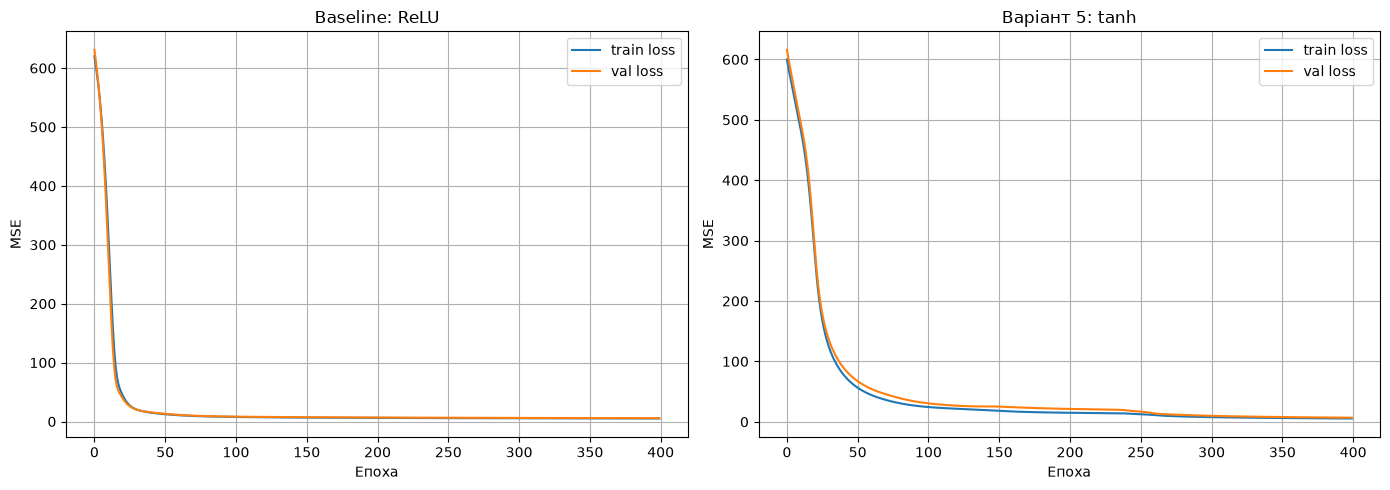

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_baseline.history["loss"], label="train loss")
axes[0].plot(history_baseline.history["val_loss"], label="val loss")
axes[0].set_title("Baseline: ReLU")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("MSE")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history_variant.history["loss"], label="train loss")
axes[1].plot(history_variant.history["val_loss"], label="val loss")
axes[1].set_title("Варіант 5: tanh")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("MSE")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Графіки навчання нейромереж

Для baseline-мережі з ReLU та моделі варіанта з tanh побудовано графіки `loss` і `val_loss`. Вони показують зміну MSE на навчальній і валідаційній вибірках. Криві використовуються для аналізу стабільності навчання, можливого перенавчання та кількості фактично виконаних епох.

In [ ]:
baseline_nn_val_pred = baseline_best_nn.predict(
    X_val_ready,
    verbose=0
).reshape(-1)

variant_nn_val_pred = variant_best_nn.predict(
    X_val_ready,
    verbose=0
).reshape(-1)

validation_results = pd.DataFrame([
    {
        "Модель": "DummyRegressor",
        **regression_metrics(y_val, dummy_val_pred)
    },
    {
        "Модель": "LinearRegression",
        **regression_metrics(y_val, linear_val_pred)
    },
    {
        "Модель": "Neural network (ReLU)",
        **regression_metrics(y_val, baseline_nn_val_pred),
        "Кількість епох": len(history_baseline.history["loss"]),
        "Найкраща епоха": baseline_best_epoch
    },
    {
        "Модель": "Neural network (tanh)",
        **regression_metrics(y_val, variant_nn_val_pred),
        "Кількість епох": len(history_variant.history["loss"]),
        "Найкраща епоха": variant_best_epoch
    }
])

display(validation_results.round(3))

if (
    validation_results.loc[
        validation_results["Модель"] == "Neural network (tanh)", "RMSE"
    ].iloc[0]
    <
    validation_results.loc[
        validation_results["Модель"] == "Neural network (ReLU)", "RMSE"
    ].iloc[0]
):
    best_nn = variant_best_nn
    best_nn_name = "Neural network (tanh)"
else:
    best_nn = baseline_best_nn
    best_nn_name = "Neural network (ReLU)"

best_overall_name = validation_results.loc[
    validation_results["RMSE"].idxmin(),
    "Модель"
]

print("Краща нейромережа за validation RMSE:", best_nn_name)
print("Кращий алгоритм загалом за validation RMSE:", best_overall_name)

,Модель,MAE,RMSE,R2,Кількість епох,Найкраща епоха
0,DummyRegressor,7.355,8.612,-0.000,NaN,NaN
1,LinearRegression,2.901,3.610,0.824,NaN,NaN
2,Neural network (ReLU),1.811,2.393,0.923,400.0,399.0
3,Neural network (tanh),1.917,2.617,0.908,400.0,400.0


Краща нейромережа за validation RMSE: Neural network (ReLU)
Кращий алгоритм загалом за validation RMSE: Neural network (ReLU)


## Вибір моделі за validation

Сформовано таблицю validation MAE, RMSE і R² для DummyRegressor, LinearRegression та двох нейромереж. Кращу нейромережу й найкращий алгоритм загалом обрано за найменшим validation RMSE. Рішення прийнято до оцінювання test-вибірки, тому test залишився незалежним для фінальної перевірки.

In [ ]:
dummy_test_pred = dummy_model.predict(X_test_ready)
linear_test_pred = linear_model.predict(X_test_ready)

baseline_nn_test_pred = baseline_best_nn.predict(
    X_test_ready,
    verbose=0
).reshape(-1)

variant_nn_test_pred = variant_best_nn.predict(
    X_test_ready,
    verbose=0
).reshape(-1)

final_results = pd.DataFrame([
    {
        "Модель": "DummyRegressor",
        "Validation RMSE": validation_results.loc[0, "RMSE"],
        **{
            f"Test {key}": value
            for key, value in regression_metrics(y_test, dummy_test_pred).items()
        }
    },
    {
        "Модель": "LinearRegression",
        "Validation RMSE": validation_results.loc[1, "RMSE"],
        **{
            f"Test {key}": value
            for key, value in regression_metrics(y_test, linear_test_pred).items()
        }
    },
    {
        "Модель": "Neural network (ReLU)",
        "Validation RMSE": validation_results.loc[2, "RMSE"],
        "Кількість епох": len(history_baseline.history["loss"]),
        "Найкраща епоха": baseline_best_epoch,
        **{
            f"Test {key}": value
            for key, value in regression_metrics(
                y_test,
                baseline_nn_test_pred
            ).items()
        }
    },
    {
        "Модель": "Neural network (tanh)",
        "Validation RMSE": validation_results.loc[3, "RMSE"],
        "Кількість епох": len(history_variant.history["loss"]),
        "Найкраща епоха": variant_best_epoch,
        **{
            f"Test {key}": value
            for key, value in regression_metrics(
                y_test,
                variant_nn_test_pred
            ).items()
        }
    }
])

display(final_results.round(3))

,Модель,Validation RMSE,Test MAE,Test RMSE,Test R2,Кількість епох,Найкраща епоха
0,DummyRegressor,8.612,6.068,7.488,-0.001,NaN,NaN
1,LinearRegression,3.610,2.402,3.058,0.833,NaN,NaN
2,Neural network (ReLU),2.393,1.708,2.284,0.907,400.0,399.0
3,Neural network (tanh),2.617,1.846,2.380,0.899,400.0,400.0


## Фінальна оцінка на test

Після вибору моделей за validation усі чотири фінальні моделі один раз оцінено на незалежній test-вибірці. Для кожної моделі наведено validation RMSE, test MAE, test RMSE і test R². Test-результати використовуються для чесної підсумкової оцінки, а не для зміни налаштувань або вибору моделі.

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,actual_mpg,predicted_mpg,residual,absolute_error
377,4,91.0,68.0,1970.0,17.6,82,3,31.0,38.262001,-7.262,7.262
30,4,140.0,90.0,2264.0,15.5,71,1,28.0,22.423000,5.577,5.577
389,6,232.0,112.0,2835.0,14.7,82,1,22.0,27.294001,-5.294,5.294
341,6,173.0,110.0,2725.0,12.6,81,1,23.5,28.129000,-4.629,4.629
298,8,350.0,125.0,3900.0,17.4,79,1,23.0,18.582001,4.418,4.418


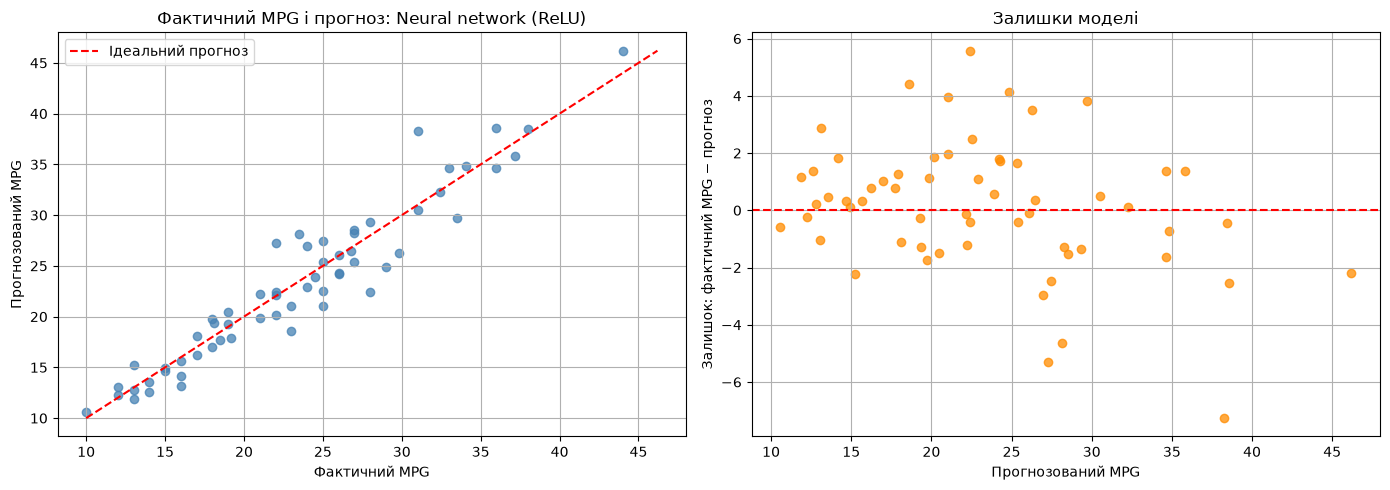

In [ ]:
if best_nn_name == "Neural network (tanh)":
    best_nn_test_pred = variant_nn_test_pred
else:
    best_nn_test_pred = baseline_nn_test_pred

residuals = y_test.to_numpy() - best_nn_test_pred

error_analysis = X_test.copy()
error_analysis["actual_mpg"] = y_test.to_numpy()
error_analysis["predicted_mpg"] = best_nn_test_pred
error_analysis["residual"] = residuals
error_analysis["absolute_error"] = np.abs(residuals)

largest_errors = error_analysis.sort_values(
    "absolute_error",
    ascending=False
).head(5)

display(largest_errors.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

min_value = min(y_test.min(), best_nn_test_pred.min())
max_value = max(y_test.max(), best_nn_test_pred.max())

axes[0].scatter(
    y_test,
    best_nn_test_pred,
    alpha=0.75,
    color="steelblue"
)
axes[0].plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Ідеальний прогноз"
)
axes[0].set_title(f"Фактичний MPG і прогноз: {best_nn_name}")
axes[0].set_xlabel("Фактичний MPG")
axes[0].set_ylabel("Прогнозований MPG")
axes[0].legend()
axes[0].grid(True)

axes[1].scatter(
    best_nn_test_pred,
    residuals,
    alpha=0.75,
    color="darkorange"
)
axes[1].axhline(y=0, color="red", linestyle="--")
axes[1].set_title("Залишки моделі")
axes[1].set_xlabel("Прогнозований MPG")
axes[1].set_ylabel("Залишок: фактичний MPG − прогноз")
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Аналіз помилок кращої нейромережі

Для кращої за validation нейромережі побудовано графік фактичного MPG проти прогнозу та графік залишків. Точки поблизу діагоналі відповідають точним прогнозам. Додатні залишки означають недооцінювання MPG, а від’ємні — переоцінювання. Окремо показано п’ять найбільших абсолютних помилок разом з ознаками автомобілів; можливими причинами є обмежена кількість ознак, шум у даних і невеликий розмір набору.

In [ ]:
final_model_path = artifacts_dir / "lab6_model.keras"
preprocessor_path = artifacts_dir / "preprocessor.joblib"
metadata_path = artifacts_dir / "metadata.json"

best_nn.save(final_model_path)
joblib.dump(preprocessor, preprocessor_path)

if best_overall_name == "LinearRegression":
    joblib.dump(
        linear_model,
        artifacts_dir / "best_classic_model.joblib"
    )
elif best_overall_name == "DummyRegressor":
    joblib.dump(
        dummy_model,
        artifacts_dir / "best_classic_model.joblib"
    )

metadata = {
    "seed": SEED,
    "target": "mpg",
    "target_unit": "miles per gallon",
    "source": "UCI Auto MPG, DOI: 10.24432/C5859H",
    "license": "CC BY 4.0",
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "prepared_feature_names": feature_names.tolist(),
    "best_neural_network": best_nn_name,
    "best_overall_model": best_overall_name,
    "versions": {
        "tensorflow": tf.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "joblib": joblib.__version__
    },
    "train_indices": [int(index) for index in X_train.index],
    "validation_indices": [int(index) for index in X_val.index],
    "test_indices": [int(index) for index in X_test.index]
}

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, ensure_ascii=False, indent=2)

restored_preprocessor = joblib.load(preprocessor_path)
restored_model = keras.models.load_model(final_model_path)

new_cars = pd.DataFrame({
    "cylinders": [4, 6, 8],
    "displacement": [140.0, 250.0, 350.0],
    "horsepower": [90.0, 120.0, 160.0],
    "weight": [2400.0, 3200.0, 4000.0],
    "acceleration": [15.0, 14.0, 12.0],
    "model_year": [76, 80, 73],
    "origin": [1, 2, 3]
})

new_cars_ready = restored_preprocessor.transform(
    new_cars
).astype(np.float32)

original_predictions = best_nn.predict(
    new_cars_ready,
    verbose=0
)

restored_predictions = restored_model.predict(
    new_cars_ready,
    verbose=0
)

np.testing.assert_allclose(
    original_predictions,
    restored_predictions,
    rtol=1e-5,
    atol=1e-6
)

print("Модель збережено:", final_model_path)
print("Препроцесор збережено:", preprocessor_path)
print("Metadata збережено:", metadata_path)
print("Перевірку відновлення моделі пройдено.")
display(pd.DataFrame({
    "Прогноз MPG": restored_predictions.reshape(-1)
}).round(3))

Модель збережено: artifacts\lab6_model.keras
Препроцесор збережено: artifacts\preprocessor.joblib
Metadata збережено: artifacts\metadata.json
Перевірку відновлення моделі пройдено.


,Прогноз MPG
0,26.059999
1,19.719999
2,4.617000


## Збереження та відновлення результату

Кращу нейромережу збережено у `artifacts/lab6_model.keras`, а препроцесор — у `artifacts/preprocessor.joblib`. У `metadata.json` записано seed, версії бібліотек, ознаки, порядок підготовлених стовпців та індекси вибірок. Після завантаження моделі й препроцесора виконано прогноз для трьох сирих рядків. Збіг прогнозів до та після відновлення підтверджено з допустимою похибкою обчислень.

In [ ]:
validation_results.to_csv(
    "validation_results.csv",
    index=False
)

final_results.to_csv(
    "final_results.csv",
    index=False
)

largest_errors.to_csv(
    "largest_errors.csv",
    index=False
)

requirements_text = "\n".join([
    f"tensorflow=={tf.__version__}",
    f"numpy=={np.__version__}",
    f"pandas=={pd.__version__}",
    f"matplotlib=={plt.matplotlib.__version__}",
    f"scikit-learn=={sklearn.__version__}",
    f"joblib=={joblib.__version__}"
])

Path("requirements.txt").write_text(
    requirements_text + "\n",
    encoding="utf-8"
)

print("Збережено:")
print("- validation_results.csv")
print("- final_results.csv")
print("- largest_errors.csv")
print("- requirements.txt")

Збережено:
- validation_results.csv
- final_results.csv
- largest_errors.csv
- requirements.txt


## Файли результатів

Окремо збережено таблиці validation-результатів, test-результатів і найбільших помилок у форматі CSV. Також створено `requirements.txt` із версіями використаних бібліотек. Це дає змогу відтворити експеримент та перевірити отримані результати поза ноутбуком.

In [ ]:
from IPython.display import Markdown, display

best_overall_rmse = validation_results.loc[
    validation_results["Модель"] == best_overall_name,
    "RMSE"
].iloc[0]

best_nn_rmse = validation_results.loc[
    validation_results["Модель"] == best_nn_name,
    "RMSE"
].iloc[0]

if best_overall_name == best_nn_name:
    model_conclusion = (
        f"Кращим алгоритмом за validation RMSE стала {best_overall_name} "
        f"із RMSE = {best_overall_rmse:.3f}, тому в цьому експерименті "
        "нейромережа виправдала свою складність."
    )
else:
    model_conclusion = (
        f"Кращим алгоритмом за validation RMSE стала {best_overall_name} "
        f"із RMSE = {best_overall_rmse:.3f}, тоді як краща нейромережа "
        f"({best_nn_name}) мала RMSE = {best_nn_rmse:.3f}. "
        "Отже, у цьому експерименті нейромережа не виправдала додаткову складність."
    )

conclusion = f"""
## Висновок

У роботі підготовлено реальні табличні дані Auto MPG без витоку інформації: імпутацію, one-hot кодування та нормалізацію навчено лише на train-вибірці. {model_conclusion}  
У варіанті 5 змінено лише функцію активації прихованих шарів з `relu` на `tanh`, а рішення про кращу модель прийнято за validation RMSE.  
Фінальні метрики MAE, RMSE та R² отримано на test-вибірці лише після вибору моделі, тому оцінка є незалежною.  
Обмеженнями експерименту є невеликий історичний набір даних, обмежена кількість ознак і відсутність гарантії, що модель підходить для сучасного автопарку.
"""

display(Markdown(conclusion))


## Висновок

У роботі підготовлено реальні табличні дані Auto MPG без витоку інформації: імпутацію, one-hot кодування та нормалізацію навчено лише на train-вибірці. Кращим алгоритмом за validation RMSE стала Neural network (ReLU) із RMSE = 2.393, тому в цьому експерименті нейромережа виправдала свою складність.  
У варіанті 5 змінено лише функцію активації прихованих шарів з `relu` на `tanh`, а рішення про кращу модель прийнято за validation RMSE.  
Фінальні метрики MAE, RMSE та R² отримано на test-вибірці лише після вибору моделі, тому оцінка є незалежною.  
Обмеженнями експерименту є невеликий історичний набір даних, обмежена кількість ознак і відсутність гарантії, що модель підходить для сучасного автопарку.
